# Test Notebook zum ausprobieren

Dieses Notebook kann sich jeder herunterladen und ein wenig ausprobieren. Zuerst aber bitte folgende Informationen lesen:

- Installiere bitte folgende Pakete im Terminal (`bash` order `command prompt`): `pip install <package>`:
    - pandas
    - matplotlib
    - numpy
    - seaborn

- Es wird ein öffentlich zugängliches Datenset geladen, welches für ein minimales Processing und Visualisierung verwendet wird.

- Im Anschluss finden sich noch ein paar kleinere Funktionen, mit dene verschiedener Code ausprobiert werden kann.

# Dataset
## Information
The Iris flower data set is a multivariate data set introduced by the British statistician and biologist Ronald Fisher in his 1936 paper *The use of multiple measurements in taxonomic problems*. It is sometimes called Anderson's Iris data set because Edgar Anderson collected the data to quantify the morphologic variation of Iris flowers of three related species. The data set consists of 50 samples from each of three species of Iris (Iris Setosa, Iris virginica, and Iris versicolor). Four features were measured from each sample: the length and the width of the sepals and petals, in centimeters.

This dataset became a typical test case for many statistical classification techniques in machine learning such as support vector machines.

## Content
The dataset contains a set of 150 records under 5 attributes - Petal Length, Petal Width, Sepal Length, Sepal width and Class(Species).

![Iris Flower Dataset](https://miro.medium.com/v2/resize:fit:1100/format:webp/1*ZK9_HrpP_lhSzTq9xVJUQw.png)
*Source: [Medium](https://medium.com/)*

___

# Code
## Laden von Paketen und des Datensets

In [25]:
# Diese Zelle importiert packages und muss immer zu Beginn ausgeführt werden

import matplotlib.pyplot as plt # plotting
import numpy as np # linear algebra
import os # accessing directory structure
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns # plotting

In [26]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data"
columns = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'class']
iris_df = pd.read_csv(url, names=columns)

In [27]:
display(iris_df)

,sepal_length,sepal_width,petal_length,petal_width,class
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,Iris-virginica
146,6.3,2.5,5.0,1.9,Iris-virginica
147,6.5,3.0,5.2,2.0,Iris-virginica
148,6.2,3.4,5.4,2.3,Iris-virginica


In [28]:
iris_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   class         150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


In [29]:
from pandas.api.types import is_numeric_dtype

for col in iris_df.columns:
    if is_numeric_dtype(iris_df[col]):
        print(col)
        print(f'\t Mean = {iris_df[col].mean():.2f}')
        print(f'\t Standard deviation = {iris_df[col].std():.2f}')
        print(f'\t Minimum = {iris_df[col].min():.2f}')
        print(f'\t Maximum = {iris_df[col].max():.2f}')

sepal_length
	 Mean = 5.84
	 Standard deviation = 0.83
	 Minimum = 4.30
	 Maximum = 7.90
sepal_width
	 Mean = 3.05
	 Standard deviation = 0.43
	 Minimum = 2.00
	 Maximum = 4.40
petal_length
	 Mean = 3.76
	 Standard deviation = 1.76
	 Minimum = 1.00
	 Maximum = 6.90
petal_width
	 Mean = 1.20
	 Standard deviation = 0.76
	 Minimum = 0.10
	 Maximum = 2.50


## Preprocessing

Zum Preprocessing gehören unterschiedliche Schritte, je nach den zugrunde liegenden Daten. 

Häufige Schritte sind aber:
- data cleaning: Duplikate und irrelevante Informationen entfernen, fehlerhafte Daten korrigieren und der Umgang mit fehlenden Daten
- Normalisierung/Skalierung: Normalisierung oder Skalierung hilft numerische Daten auf eine einheitliche Skala zu bringen, oder auch mit Ausreißern umzugehen
- Codierung von kategorischen Daten: Kategorien können in numerische Daten umgewandelt werden, um in Models verwendet werden zu können
- Data Splitting: Aufteilung in Training, Test und Validierungsdatensatz
- Dimensionsreduktion: Bei einer großen Anzahl von Features (Variablen) kann die Reduktion auf wichtige Features sinnvoll sein.

Prinzipiell ist das Ziel des Preprocessings immer die Daten in eine Form zu bringen, in der sie für weitere Analysen oder Modeling verwendet werden können.

In [30]:
# Überprüfen von fehlenden Werten
iris_df.isnull().sum()

sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
class           0
dtype: int64

In [31]:
# Duplikate überprüfen und entfernen
duplicates = iris_df[iris_df.duplicated()]
print("Anzahl an Duplikaten:", len(duplicates))

if len(duplicates) > 0:
    iris_df = iris_df.drop_duplicates()

Anzahl an Duplikaten: 3


In [32]:
# Ausreißer überprüfen
iris_df.describe().round(3)

,sepal_length,sepal_width,petal_length,petal_width
count,147.000,147.000,147.000,147.000
mean,5.856,3.056,3.780,1.209
std,0.829,0.437,1.759,0.758
min,4.300,2.000,1.000,0.100
25%,5.100,2.800,1.600,0.300
50%,5.800,3.000,4.400,1.300
75%,6.400,3.300,5.100,1.800
max,7.900,4.400,6.900,2.500


In [33]:
# Korrelationen von numerischen Variablen überprüfen
iris_df.drop('class', axis = 1).corr().round(3)

,sepal_length,sepal_width,petal_length,petal_width
sepal_length,1.000,-0.109,0.871,0.817
sepal_width,-0.109,1.000,-0.421,-0.356
petal_length,0.871,-0.421,1.000,0.962
petal_width,0.817,-0.356,0.962,1.000


In [34]:
# skewness (Schiefe) für alle numerischen Variablen berechnen
# skewness = 0: Daten sind symmetrisch
# skewness > 0: Daten sind linksverschoben
# skewness < 0: Daten sind rechtsverschoben

In [35]:
iris_df.drop('class', axis = 1).skew().round(3)

sepal_length    0.293
sepal_width     0.324
petal_length   -0.294
petal_width    -0.113
dtype: float64

In [36]:
# Anzahl von unique Werten
iris_df.nunique()

sepal_length    35
sepal_width     23
petal_length    43
petal_width     22
class            3
dtype: int64

In [37]:
# Anzahl der Arten zählen
iris_df["class"].value_counts()

class
Iris-versicolor    50
Iris-virginica     49
Iris-setosa        48
Name: count, dtype: int64

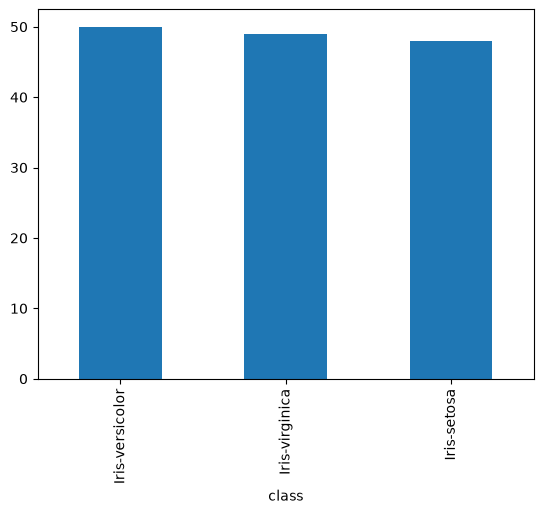

In [38]:
iris_df['class'].value_counts().plot(kind='bar')
plt.show()

## Datenvisualisierung
Es gibt viele Gründe für die Visualisierung:
- Trends und Muster identifizieren
- Daten können so leichter kommuniziert werden
- Vergleich von Daten
- Identifizierung von Ausreißern
- Verteilung beurteilen

In [ ]:
# Visualize the whole dataset

sns.pairplot(iris_df,hue="class")
plt.show()

Es besteht eine große Korrelation zwischen petal length und petal width. Die Setosa Klasse hat sowohl eine niedrige petal length und petal width, während die Versicolor Klasse Klasse in beiden durchschnittliche Werte hat. Die Virginica Klasse hingegen hat sowohl eine große petal length und petal with. Bei den sepal Daten hat die Setosa Klasse eine große width und niedrige length. Die Versicolor Klasse hat bei beidem durchschnittliche Werte. Die Virginica Klasse hat eine kleine sepal width aber eine große sepal length.

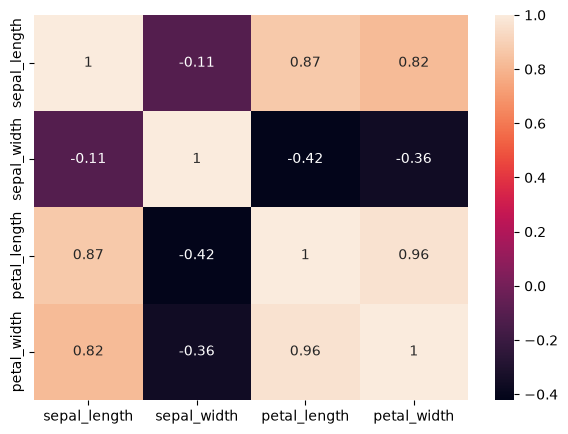

In [ ]:
plt.figure(figsize=(7,5))
# Plotting the heatmap
sns.heatmap(iris_df.drop('class', axis = 1).corr(), annot=True)
plt.show()

Sepal length und width korrelieren leicht.

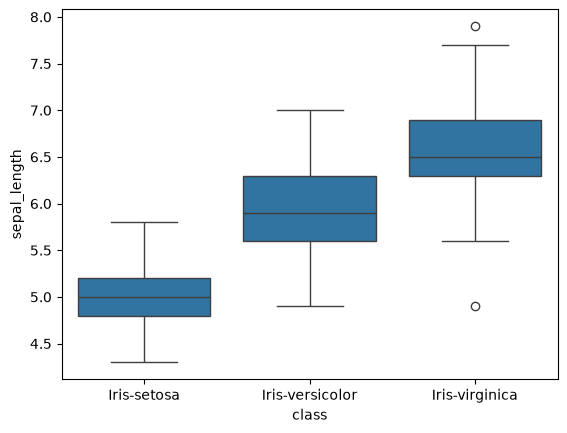

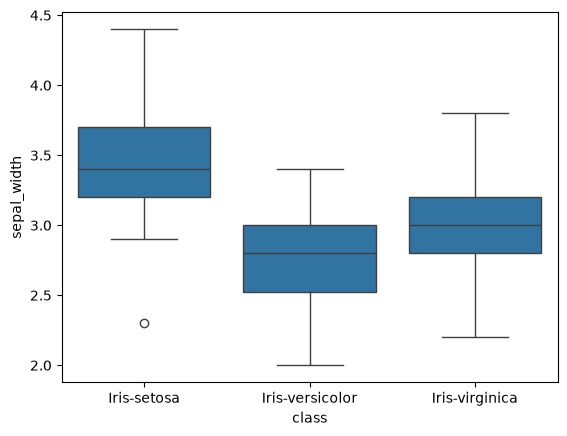

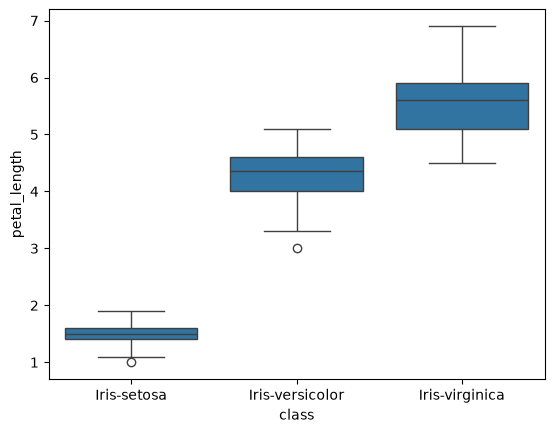

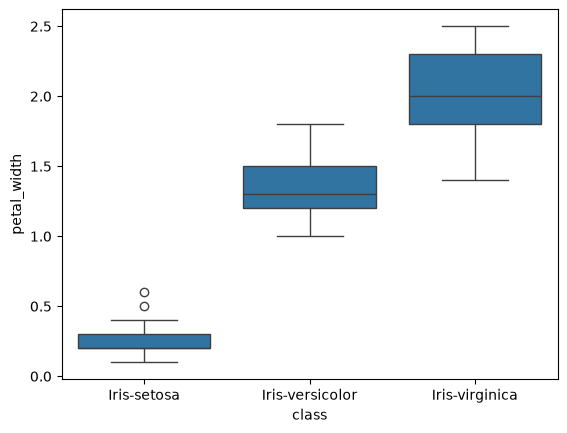

In [ ]:
# Boxplots
sns.boxplot(x='class', y='sepal_length', data=iris_df)
plt.show()

sns.boxplot(x='class', y='sepal_width', data=iris_df)
plt.show()

sns.boxplot(x='class', y='petal_length', data=iris_df)
plt.show()

sns.boxplot(x='class', y='petal_width', data=iris_df)
plt.show()

The Setosa species has smaller and less distributed features compared to the other two species. The Versicolor species is distributed in an average manner and has average-sized features. The Virginica species, on the other hand, is highly distributed with a large number of values and features. The mean and median values of various features (such as sepal length and width, and petal length and width) are clearly shown by each plot for each species. This suggests that the distribution of these features varies significantly between the three species.

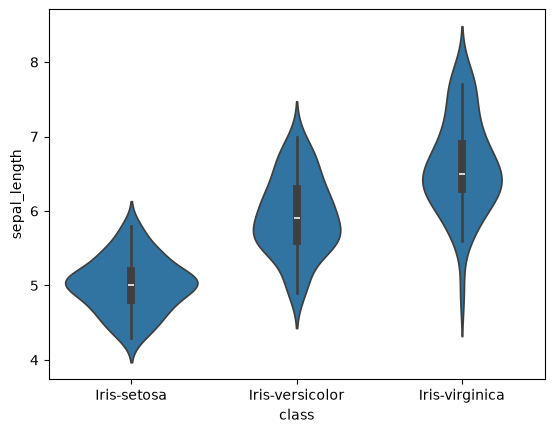

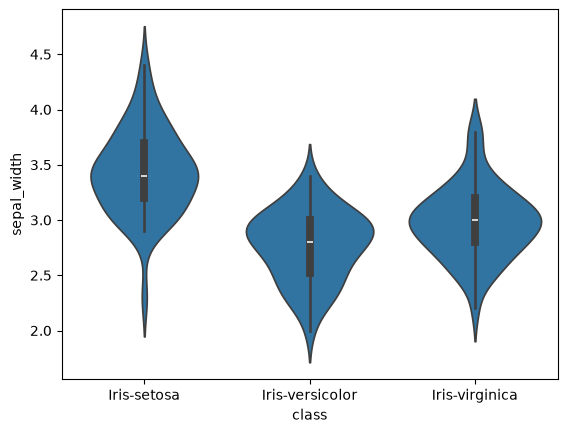

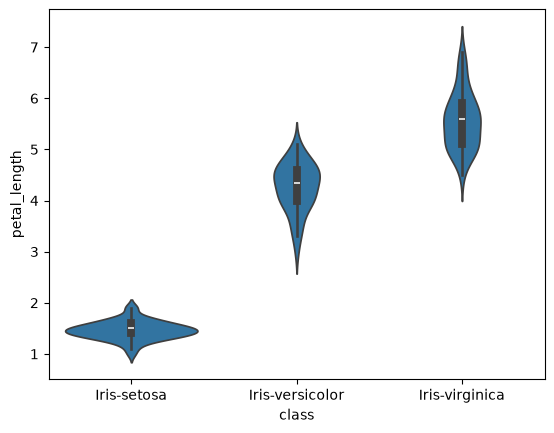

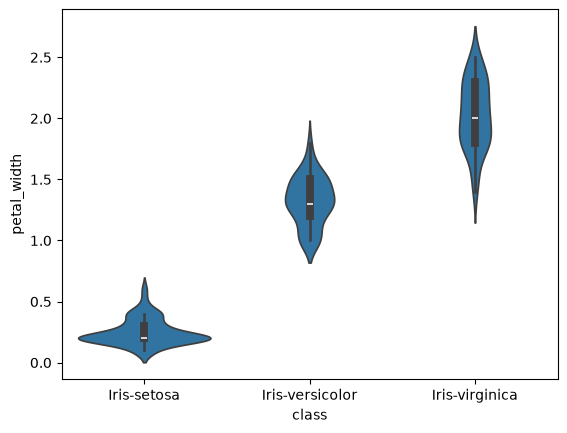

In [ ]:
# Violinplot
sns.violinplot(x='class', y='sepal_length', data=iris_df)
plt.show()

sns.violinplot(x='class', y='sepal_width', data=iris_df)
plt.show()

sns.violinplot(x='class', y='petal_length', data=iris_df)
plt.show()

sns.violinplot(x='class', y='petal_width', data=iris_df)
plt.show()

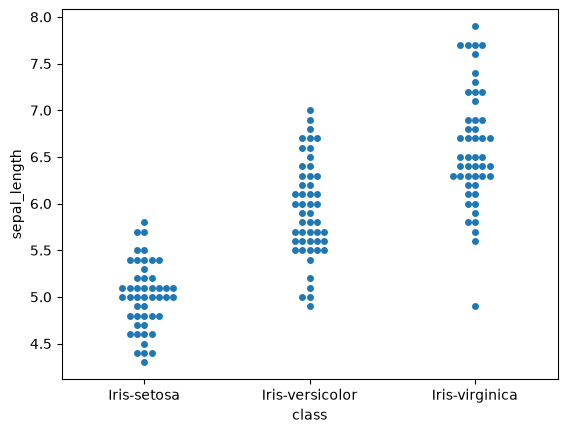

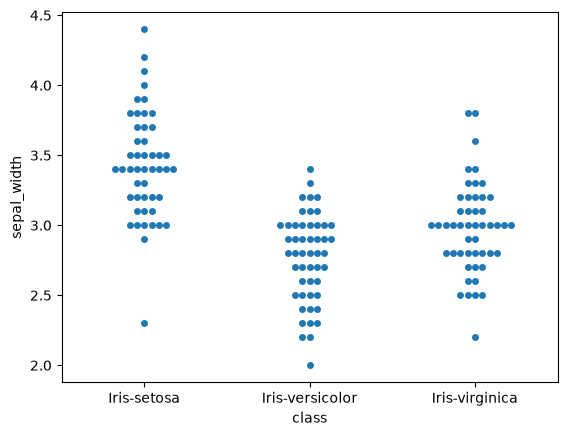

/home/ag10337/dissertation/.venv/lib/python3.14/site-packages/seaborn/categorical.py:3399: UserWarning: 6.2% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


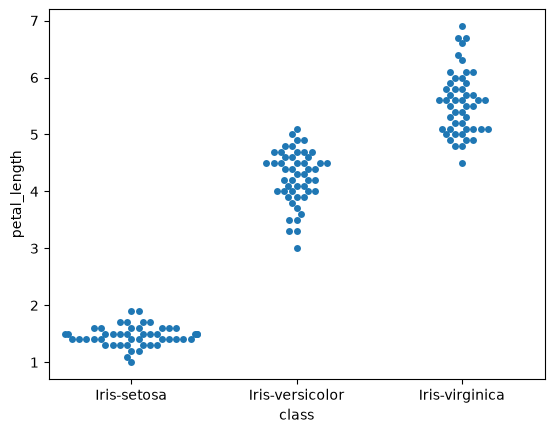

/home/ag10337/dissertation/.venv/lib/python3.14/site-packages/seaborn/categorical.py:3399: UserWarning: 6.2% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/home/ag10337/dissertation/.venv/lib/python3.14/site-packages/seaborn/categorical.py:3399: UserWarning: 18.8% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


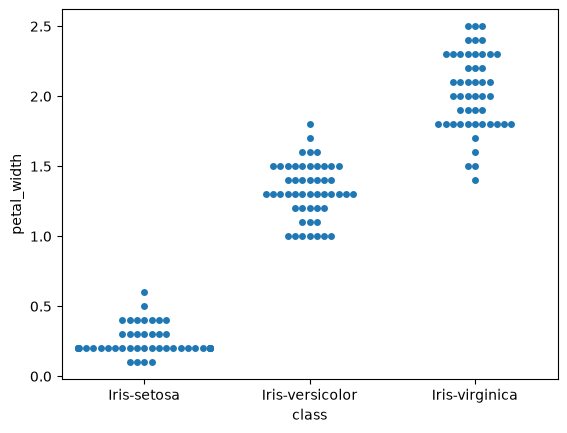

In [ ]:
# Swarmplot
sns.swarmplot(x='class', y='sepal_length', data=iris_df)
plt.show()

sns.swarmplot(x='class', y='sepal_width', data=iris_df)
plt.show()

sns.swarmplot(x='class', y='petal_length', data=iris_df)
plt.show()

sns.swarmplot(x='class', y='petal_width', data=iris_df)
plt.show()

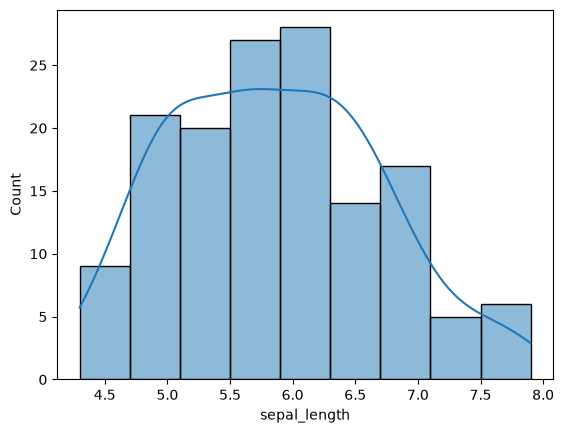

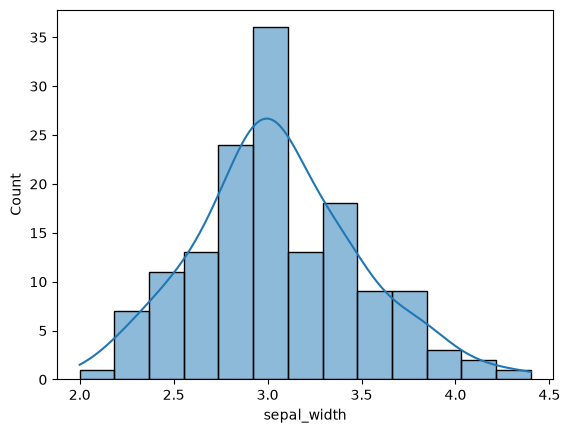

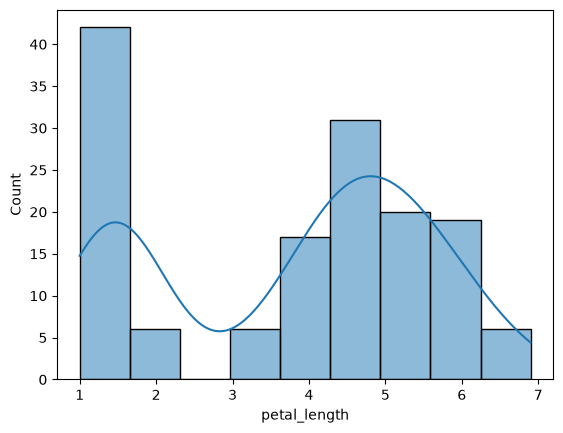

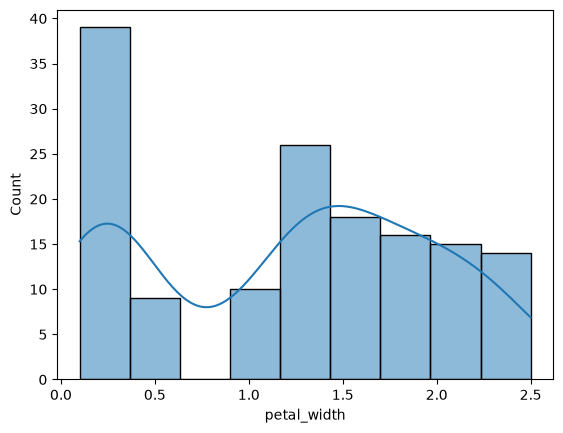

In [ ]:
# Distplot
sns.histplot(iris_df['sepal_length'], kde=True)
plt.show()

sns.histplot(iris_df['sepal_width'], kde=True)
plt.show()

sns.histplot(iris_df['petal_length'], kde=True)
plt.show()

sns.histplot(iris_df['petal_width'], kde=True)
plt.show()

___

## Beispiele

In [ ]:
def addition(a,b):
    return a+b

def subtraktion(a,b):
    return a-b 

def multiplikation(a,b):
    return a*b

def division(a,b):
    return a/b

In [ ]:
print('Addition von 2 und 3:', addition(2,3))
print('Addition von 2.3 und 7.4:',addition(2.3, 7.4))

print('Division funktioniert auch für gleichlange Spalten:\n',division(iris_df['sepal_length'], iris_df['petal_length']))


Addition von 2 und 3: 5
Addition von 2.3 und 7.4: 9.7
Division funktioniert auch für gleichlange Spalten:
 0      3.642857
1      3.500000
2      3.615385
3      3.066667
4      3.571429
         ...   
145    1.288462
146    1.260000
147    1.250000
148    1.148148
149    1.156863
Length: 147, dtype: float64


In [ ]:
def my_function(a,b):
    if a > b:
        return subtraktion(a,b)
    elif a==b:
        return multiplikation(a,b)
    elif b>a:
        return addition(a,b)

In [ ]:
print(my_function(5,9))
print(my_function(9,4))
print(my_function(4,4))

14
5
16
